## Part 3: Add Foregrounds

Create simulations at 23 GHz (WMAP), 93 GHz (CLASS), and 353 GHz (Planck) that have dust, synchrotron, and CMB. Vary the CMB between simulations but keep the same dust and synchrotron components. Clean the 93 GHz map using ILC methods and then estimate $\tau$. Repeating this across simulations, estimate the uncertainy on $\tau$. 


### Part 3:

Now, we introduce ILC. In ILC, we are fitting some parameters to add the maps of different frequencies together to remove the background. For an arbitrary number of frequencies, we could write this as a constrained problem. (Note I changed a to w so it does not get confused with the basis function coefficients in the power spectrum)
$$
\hat{\boldsymbol c}=\sum_\nu w_\nu\boldsymbol m_\nu,\qquad\sum w_\nu=1.
$$

Going from the map to the power spectra for an ILC cleaned map is complex in that there are many cross terms to sort through. In theory, we already optimized the ILC coefficients to minimize the bias from the foreground. So, we approximate the mean and variance of the power spectra (see equation 7 in [Duncan's paper](https://arxiv.org/pdf/1801.01481)).

There are a few ambiguous derivations of a general form of the variance of power spectrum for gaussian. From what I can gather, when you are dealing with a map where the data is made up of cmb + foreground, the mean and variance of the power spectrum is
$$
\langle\hat C_\ell\rangle=C^{(cmb)}_\ell + \sum_\nu w_\nu^2 N_\ell,\qquad
\mathrm{var}(\hat C_\ell)=\frac2{2\ell+1}(\langle\hat C_\ell\rangle)^2 = \frac2{2\ell+1}(C^{(cmb)}_\ell + \sum_\nu w_\nu^2 N_\ell)^2.
$$

Luckily, we have no noise in this part, so the minimization function becomes

$$
\frac12\chi^2+\frac12\sum_i\ln(2\pi\sigma_i(\tau)^2)\equiv \boxed{\frac12\sum_\ell\frac{(C_\ell(\tau)-y_\ell)^2}{\frac2{2\ell+1}C_\ell(\tau)}+\ln[2\pi\frac2{2\ell+1}C_\ell(\tau)]}
$$

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import healpy as hp
import os
import camb
from camb import model, initialpower
from scipy.optimize import minimize
from corner import corner

import os
os.environ["POLSPICE_BIN"] = "/home/viviantao1/software/PolSpice_v03-08-03/bin"

from minkasi.null_test.estimators import polspice
from minkasi import util as mt

pars = camb.CAMBparams()

In [2]:
import pysm3
# from pysm.nominal import models

# nside = 32
# npix = hp.nside2npix(nside)
# sky_config = {
#     'synchrotron' : models("s1", nside),
#     'dust' : models("d1", nside)
# }

# # initialise Sky 
# sky = pysm.Sky(sky_config)

import pysm3.units as u
nside = 32
npix = hp.nside2npix(nside)

sky = pysm3.Sky(nside=nside, preset_strings=["s0", "d0"], output_unit=u.uK_CMB)

In [3]:
# Convert foregrounds to CMB units
total23 = sky.get_emission(23 * u.GHz)
total93 = sky.get_emission(93 * u.GHz)
total353 = sky.get_emission(353 * u.GHz)

print("ORIGINAL Foreground RMS (before any conversion):")
print(f"23 GHz:  {np.std(total23):.2f}")
print(f"93 GHz:  {np.std(total93):.2f}")
print(f"353 GHz: {np.std(total353):.2f}")

print(total23.unit)
print(total93.unit)
print(total353.unit)

total23 = np.array(total23)
total93 = np.array(total93)
total353 = np.array(total353)

ORIGINAL Foreground RMS (before any conversion):
23 GHz:  149.63 uK_CMB
93 GHz:  99.07 uK_CMB
353 GHz: 5583.39 uK_CMB
uK_CMB
uK_CMB
uK_CMB


In [4]:
lmax=32
def get_Clhat(tau, lmax=lmax, raw_cl=True,
              H0=67, Ombh2=0.024, Omch2=0.12,
              As=2.1e-9, ns=0.965, ks=0.05, 
              kt=0.05, Omk=0, TCMB=2.7255, 
              mnu=0.06, r=0, YHe=0.245400,):
    '''
    Specify tau, and use other known parameters
    '''
    pars.set_cosmology(H0=H0, ombh2=Ombh2, omch2=Omch2, mnu=mnu, omk=Omk, tau=tau, TCMB=TCMB, YHe=YHe)
    pars.InitPower.set_params(As=As, ns=ns, r=r, pivot_scalar=ks, pivot_tensor=kt)
    results = camb.get_results(pars)
    powers = results.get_total_cls(lmax=lmax, CMB_unit='muK', raw_cl=True)
    TT, EE, BB, TE = powers.T
    #ls = np.arange(2, EE.shape[0]) # could add??
    return np.array([TT, EE, BB, TE])

true_tau = 0.054
ls = np.arange(2, lmax+1)
true_spectra = get_Clhat(true_tau) # ensemble average power spectrum
Z = ls*(ls+1)/(2*np.pi)
# plt.semilogx(ls, true_spectra[1][ls]*Z)
# plt.xlabel(r'$\ell$')
# plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')
# plt.title("True CMB EE Spectrum")


In [5]:
# power spectra -> map with random realization of Cl (random alm)
s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)

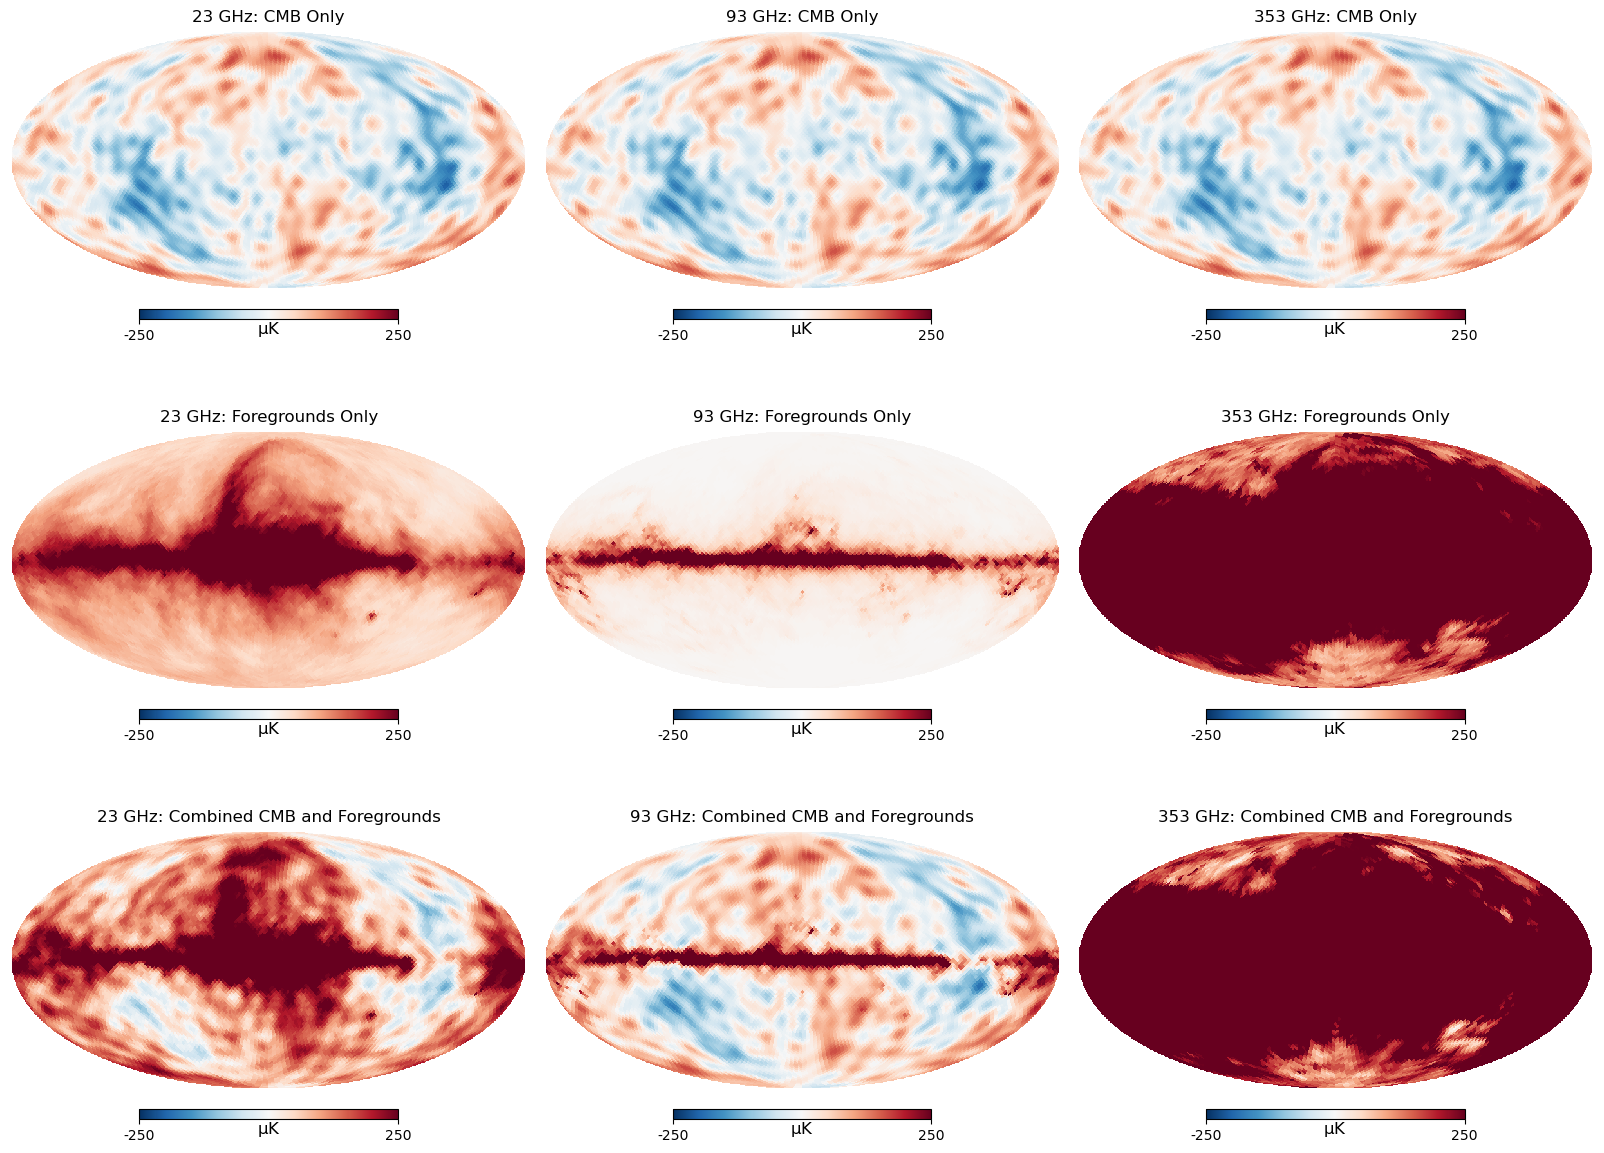

In [37]:
npix = hp.nside2npix(nside)
solid_angle = hp.nside2pixarea(nside)
# map sensitivity
noise = np.array([400, 600]) #uK arcmin
sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)

Nl = 4*np.pi * sigma_pix**2 / npix

nlow1 = np.random.randn(npix) * sigma_pix[0]
nlow2 = np.random.randn(npix) * sigma_pix[0]
nhigh1 = np.random.randn(npix) * sigma_pix[1]
nhigh2 = np.random.randn(npix) * sigma_pix[1]

combined23_1 = s + total23 + nlow1*np.sqrt(2)
combined23_2 = s + total23 + nlow2*np.sqrt(2)
combined23_12 = s + total23 + (nlow1+nlow2)/2
combined93 = s + total93
combined353_1 = s + total353 + nhigh1*np.sqrt(2)
combined353_2 = s + total353 + nhigh2*np.sqrt(2)
combined353_12 = s + total353 + (nhigh1+nhigh2)/2

plt.figure(figsize=(16, 12))

hp.mollview(s[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='23 GHz: CMB Only', sub=(3,3,1))
hp.mollview(total23[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='23 GHz: Foregrounds Only', sub=(3,3,4))
hp.mollview(combined23_1[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='23 GHz: Combined CMB and Foregrounds', sub=(3,3,7))
hp.mollview(s[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='93 GHz: CMB Only', sub=(3,3,2))
hp.mollview(total93[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='93 GHz: Foregrounds Only', sub=(3,3,5))
hp.mollview(combined93[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='93 GHz: Combined CMB and Foregrounds', sub=(3,3,8))
hp.mollview(s[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='353 GHz: CMB Only', sub=(3,3,3))
hp.mollview(total353[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='353 GHz: Foregrounds Only', sub=(3,3,6))
hp.mollview(combined353_1[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='353 GHz: Combined CMB and Foregrounds', sub=(3,3,9))

### Testing of one sim

In [38]:
temp_arr = np.array([combined23_1[0], combined93[0], combined353_1[0]])

In [8]:
def f(a, maps):
    if len(a) == 1:
        coeffs = np.array([a[0], 1-a[0]])
    else:
        coeffs = np.concatenate((a, [1-sum(a)]))
    chat = coeffs.dot(maps)
    return chat.var()

# x0 = np.zeros(len(temp_arr)-1)

# from scipy.optimize import minimize
# sol = minimize(f, x0, args=(temp_arr))

# a = np.concatenate((sol.x, np.array([1-sum(sol.x)])))

# chat = a.dot(temp_arr)
# hp.mollview(chat, min=-250, max=250, cmap='RdBu_r', title='CMB Estimate')
# hp.mollview(s[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='actual CMB')
# hp.mollview(s[0]-chat, min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='Residuals')

In [9]:
cosmic_var = np.sqrt(2/(2*ls + 1))*true_spectra[1][ls]

In [16]:
Clhat = hp.anafast(s, lmax=lmax)[1]

def make_chi2(Clhat):

    def chi2(tau):
        theory_EE = get_Clhat(tau)[1]
        return sum(((Clhat[2:33] - theory_EE[2:33])/cosmic_var)**2)
    
    return chi2
chi2 = make_chi2(Clhat)
sol = minimize(chi2, true_tau, bounds=[(0.04, 0.2)])
print(sol.x)

[0.0561127]


## Simulations

In [10]:
tau_coarse_grid = np.linspace(0.04, 0.2, 100)

EE_coarse_grid = np.array([
    get_Clhat(t)[1]
    for t in tau_coarse_grid
])

from scipy.interpolate import CubicSpline
EE_cubicspline = CubicSpline(
    tau_coarse_grid, 
    EE_coarse_grid, 
    axis=0
)

tau_grid = np.linspace(0.04, 0.2, 500)

EE_grid = EE_cubicspline(tau_grid)

In [11]:
var_grid = np.array([
    (2/(2*ls + 1))*(ee[ls])**2
    for ee in EE_grid
])

In [31]:
auto = []
cross = []

theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
b = np.degrees(np.pi/2 - theta)
l = np.degrees(phi)
# Initialize mask (1 = good, 0 = masked)
mask_gal = np.ones(npix)
# Mask galactic plane
mask_gal[np.abs(b) < 20] = 0

mask_class = mt.dec_mask(nside, [-74, 28]) #dec range for CLASS map

mask = mask_gal

for i in range(500):
    s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)
    nlow1 = np.random.randn(npix) * sigma_pix[0]
    nlow2 = np.random.randn(npix) * sigma_pix[0]
    nhigh1 = np.random.randn(npix) * sigma_pix[1]
    nhigh2 = np.random.randn(npix) * sigma_pix[1]

    combined23_1 = s + total23 + nlow1*np.sqrt(2)
    combined23_2 = s + total23 + nlow2*np.sqrt(2)
    combined23_auto = s + total23 + nlow1
    combined93 = s + total93
    combined353_1 = s + total353 + nhigh1*np.sqrt(2)
    combined353_2 = s + total353 + nhigh2*np.sqrt(2)
    combined353_auto = s + total353 + nhigh1

    chat_1 = np.empty((3, npix))
    chat_1[0] = np.zeros(npix)
    chat_2 = np.empty((3, npix))
    chat_2[0] = np.zeros(npix)
    chat_auto = np.empty((3, npix))
    chat_auto[0] = np.zeros(npix)
    Nl_eff1 = np.zeros(3)
    Nl_eff2 = np.zeros(3)
    Nl_eff3 = np.zeros(3)

    for j in (1,2):
        temp_arr_1 = np.array([combined23_1[j], combined93[j], combined353_1[j]])
        x0 = np.zeros(len(temp_arr_1)-1)
        sol = minimize(f, x0, args=(temp_arr_1))
        a1 = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
        chat_1[j] = a1.dot(temp_arr_1)

        temp_arr_2 = np.array([combined23_2[j], combined93[j], combined353_2[j]])
        x0 = np.zeros(len(temp_arr_2)-1)
        sol = minimize(f, x0, args=(temp_arr_2))
        a2 = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
        chat_2[j] = a2.dot(temp_arr_2)

        temp_arr_auto = np.array([combined23_auto[j], combined93[j], combined353_auto[j]])
        x0 = np.zeros(len(temp_arr_auto)-1)
        sol = minimize(f, x0, args=(temp_arr_auto))
        a3 = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
        chat_auto[j] = a3.dot(temp_arr_auto)

        Nl_eff1[j] = (a1[0]**2*Nl[0] + a1[2]**2*Nl[1])*2
        Nl_eff2[j] = (a2[0]**2*Nl[0] + a2[2]**2*Nl[1])*2
        Nl_eff3[j] = a3[0]**2*Nl[0] + a3[2]**2*Nl[1]

    # ------------------------ANAFAST------------------------
    # Clhat_auto = hp.anafast(chat_auto, lmax=lmax)[1]
    # Clhat_cross = hp.anafast(chat_1, chat_2, lmax=lmax)[1]

    #------------------------POLSPICE------------------------
    # mask_2d = np.zeros((2, len(mask)))
    # mask_2d[0, :] = 1.0   # Temperature weights
    # mask_2d[1, :] = mask  # Your actual Galactic mask for Polarization
    Clhat_auto = np.array(polspice(m1=chat_auto,weight1=mask,noT=True, pol=True, nlmax=lmax, apodizesigma=180.0)[1])
    Clhat_cross = np.array(polspice(m1=chat_1, m2=chat_2,weight1=mask, weight2=mask,noT=True, pol=True, nlmax=lmax, apodizesigma=180.0)[1])

    Nl_EE1 = 0.5*np.sum(Nl_eff1)
    Nl_EE2 = 0.5*np.sum(Nl_eff2)
    Nl_EE3 = 0.5*np.sum(Nl_eff3)

    var_grid_auto = np.array([
        (2/(2*ls + 1))*((ee[ls] + Nl_EE3)**2)
        for ee in EE_grid
    ])

    var_grid_cross = np.array([
        (1/(2*ls + 1))*(ee[ls]**2 + (ee[ls] + Nl_EE1)*(ee[ls] + Nl_EE2))
        for ee in EE_grid
    ])

    log_var_grid_auto = np.log(2*np.pi*var_grid_auto)
    log_var_grid_cross = np.log(2*np.pi*var_grid_cross)

    chi2_auto = np.sum(
        ((Clhat_auto[None, 2:33] - EE_grid[:, 2:33])**2 / var_grid_auto) + log_var_grid_auto,
        axis=1
    )

    chi2_cross = np.sum(
        ((Clhat_cross[None, 2:33] - EE_grid[:, 2:33])**2 / var_grid_cross) + log_var_grid_cross,
        axis=1
    )

    auto.append(tau_grid[np.argmin(chi2_auto)])
    cross.append(tau_grid[np.argmin(chi2_cross)])

auto = np.array(auto)
cross = np.array(cross)
print('done')

done


Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.003409     0.057408
Cross Spectrum                   0.003381     0.057408


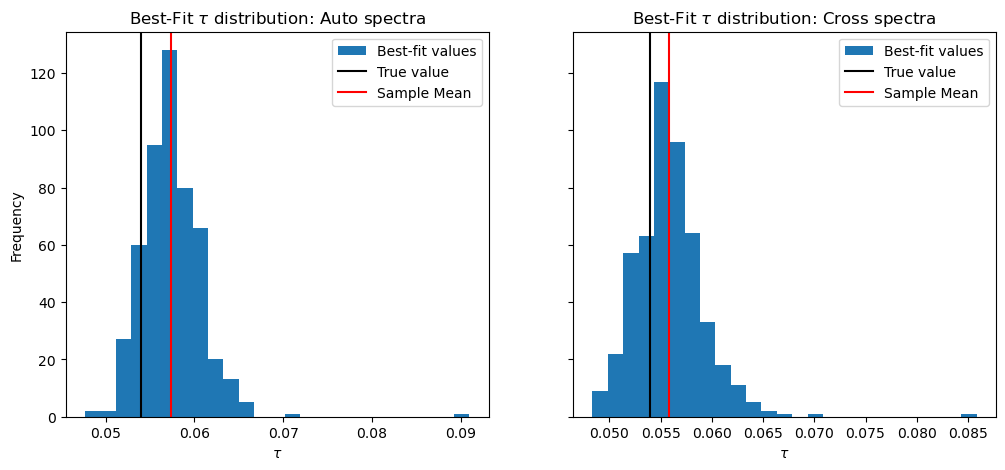

In [15]:
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.004881     0.058407
Cross Spectrum                   0.004400     0.058407


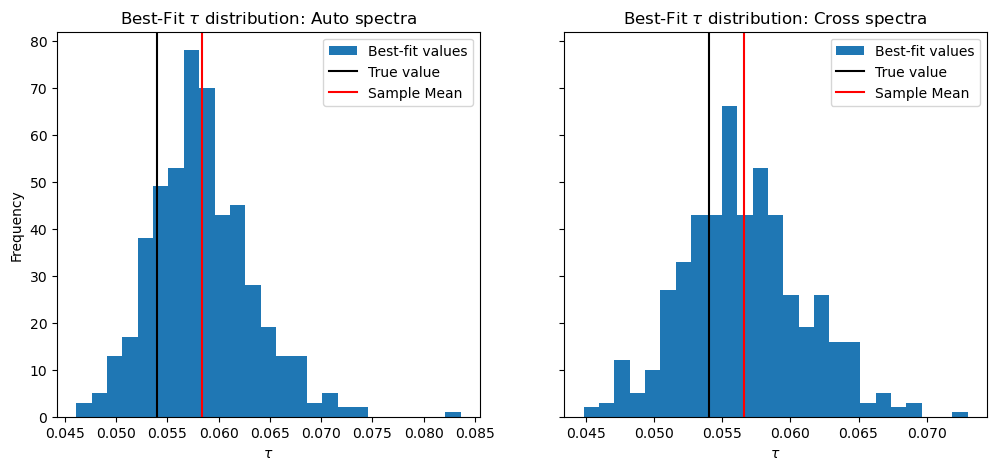

In [32]:
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

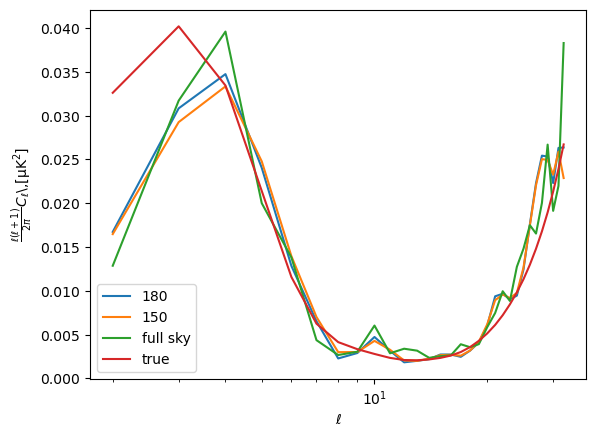

In [36]:
plt.semilogx(ls, np.array(polspice(m1=chat_auto,weight1=mask,noT=True, pol=True, nlmax=lmax, apodizesigma=180.0)[1])[ls]*Z, label='180')
plt.semilogx(ls, np.array(polspice(m1=chat_auto,weight1=mask,noT=True, pol=True, nlmax=lmax, apodizesigma=150.0)[1])[ls]*Z, label='150')
#plt.semilogx(ls, np.array(polspice(m1=chat_auto,weight1=mask,noT=True, pol=True, nlmax=lmax, apodizesigma=120.0)[1])[ls]*Z, label='120')
#plt.semilogx(ls, np.array(polspice(m1=chat_auto,weight1=mask,noT=True, pol=True, nlmax=lmax, apodizesigma=60.0)[1])[ls]*Z, label='60')
plt.semilogx(ls, hp.anafast(chat_auto, lmax=lmax)[1][ls]*Z, label='full sky')
plt.semilogx(ls, true_spectra[1][ls]*Z, label='true')
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')
#plt.title("True CMB EE Spectrum")
plt.legend()

In [13]:
print(a1)

[-0.0146002   1.03215841 -0.01755821]


## ANAFAST RESULT with s1 and d1

Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.006179     0.238799
Cross Spectrum                   0.006445     0.238799


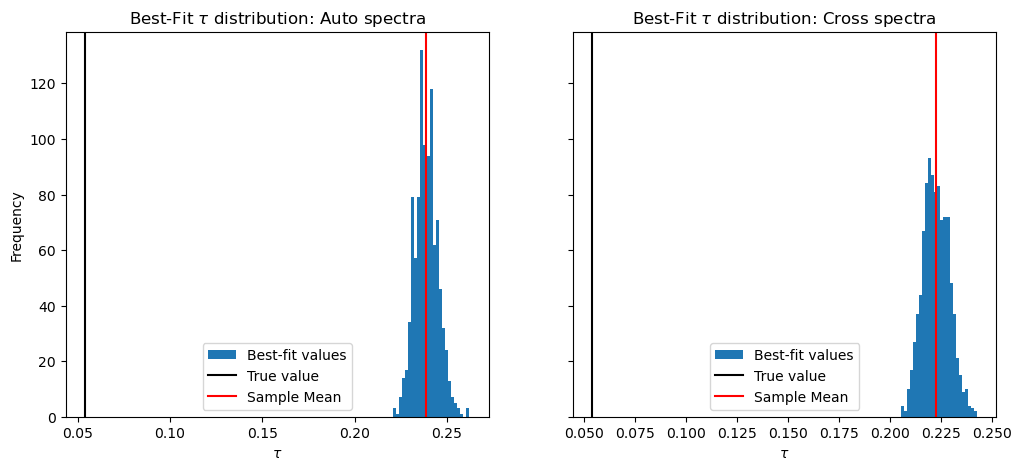

In [ ]:
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

## POLSPICE RESULT with s1 and d1 (20 degree mask)

Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.033930     0.104516
Cross Spectrum                   0.009590     0.104516


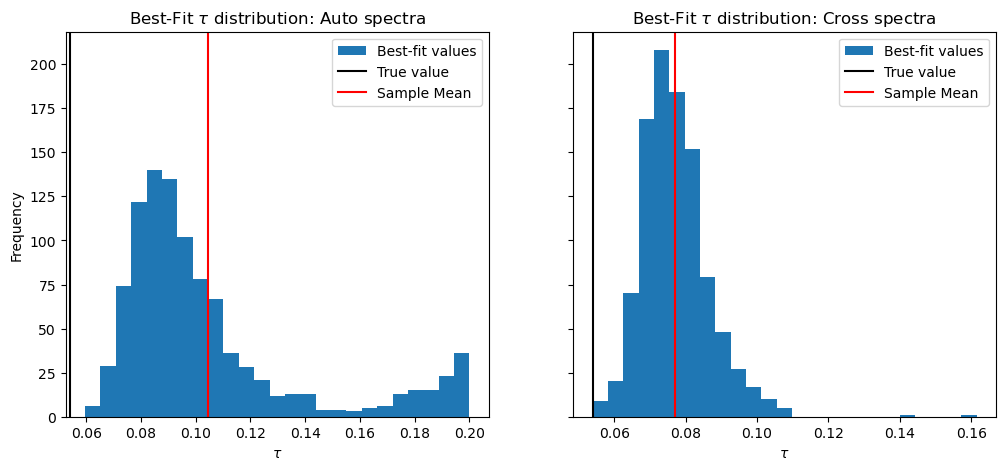

In [56]:
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

## POLSPICE RESULT with s0 and d0
### mask of 40 degrees

Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.032231     0.187771
Cross Spectrum                   0.044507     0.187771


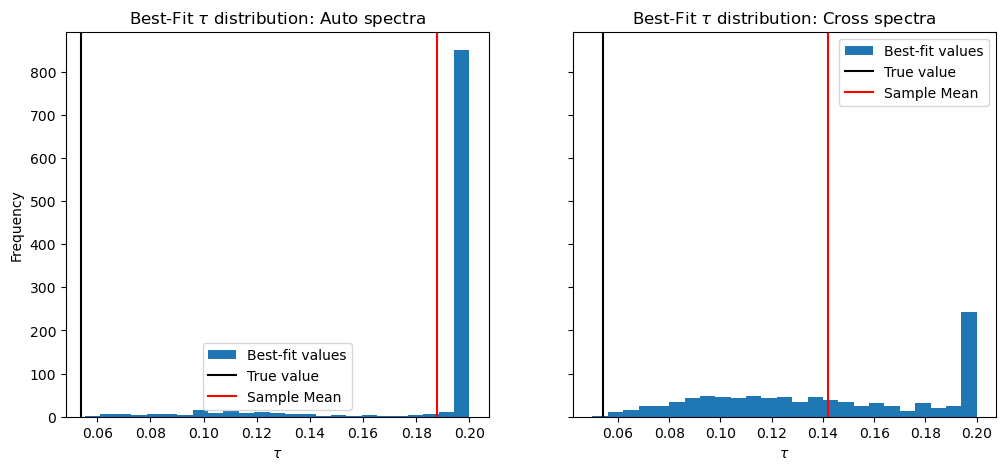

In [42]:
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

### mask of 20 degrees

Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.016338     0.073316
Cross Spectrum                   0.006338     0.073316


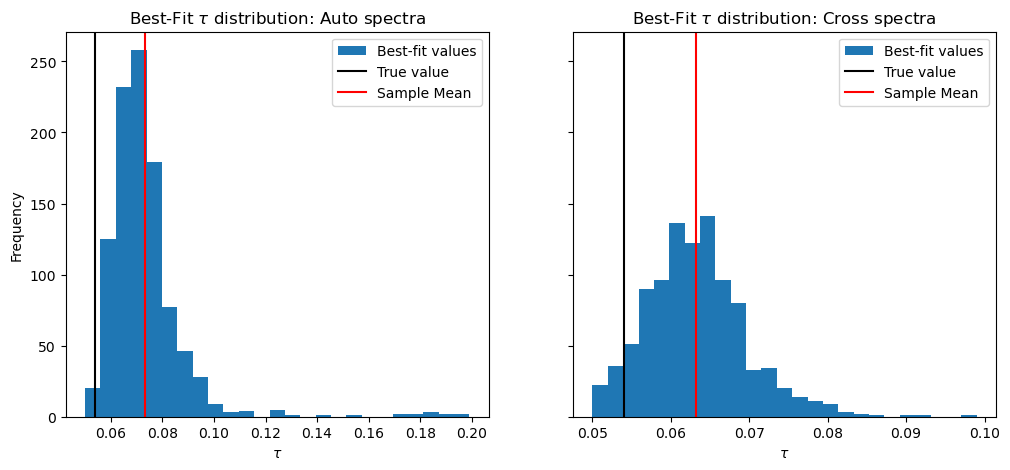

In [38]:
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

### CLASS mask

Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.032915     0.094459
Cross Spectrum                   0.019797     0.094459


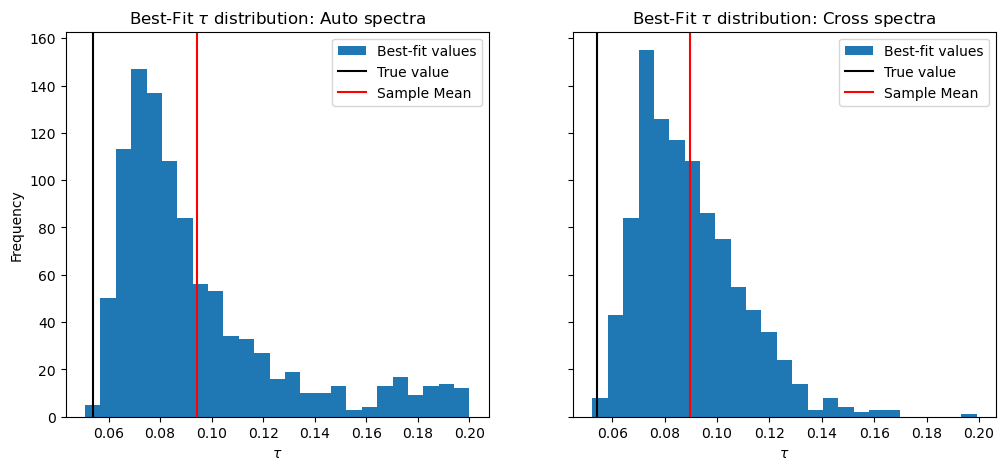

In [12]:
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

## ANAFAST RESULT with s0 and d0

Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.011694     0.073271
Cross Spectrum                   0.010015     0.073271


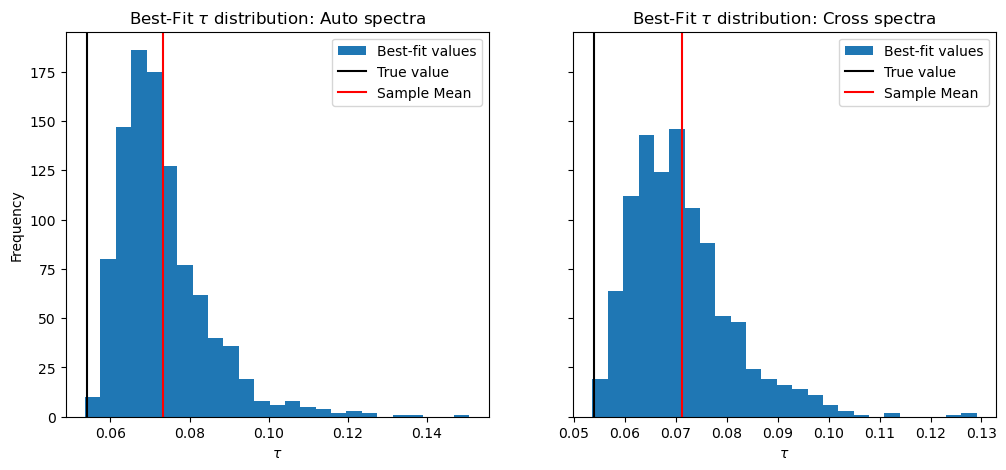

In [33]:
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

Average tau: 0.055189189189189185, Standard deviation: 0.0029407291831055463


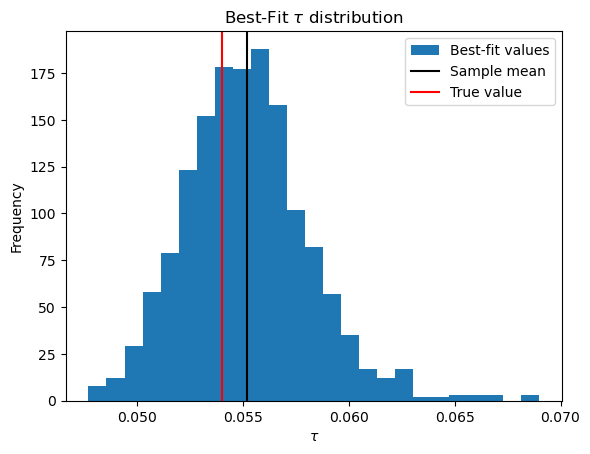

In [16]:
avg_tau = np.mean(tau_dist)
std_tau = np.std(tau_dist)

plt.hist(tau_dist, bins=25, density=False, label="Best-fit values")
plt.xlabel(r'$\tau$')
plt.ylabel("Frequency")
plt.title("Best-Fit "r'$\tau$' " distribution")
plt.axvline(avg_tau, color='black', label="Sample mean")
plt.axvline(0.054, color='red', label="True value")
#plt.axvline(avg_tau+std_tau, color='red')
#plt.axvline(tau_dist.mean()-tau_dist.std(), color='red')
plt.legend(loc='best')

print(f"Average tau: {avg_tau}, Standard deviation: {std_tau}")

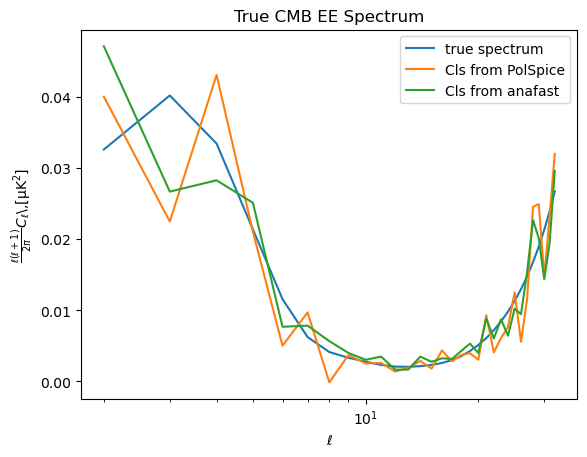

In [ ]:
import os
os.environ["POLSPICE_BIN"] = "/home/viviantao1/software/PolSpice_v03-08-03/bin"

from minkasi.null_test.estimators import polspice
from minkasi import util as mt
# m = mt.read_map(fname=MAP_PATH)
m = s
mask = mt.dec_mask(hp.get_nside(m[1]), [-74, 28]) #dec range for CLASS map
cls = polspice(m1=m,weight1=mask,noT=True) #Add m2 and weight2 for cross spectra 
#Cls = np.array([cls[1], cls[2], cls[5]]) # EE, BB, EB
Cls_EE = np.array(cls[1])
Clhat = hp.anafast(chat, lmax=lmax)[1]

plt.semilogx(ls, true_spectra[1][ls]*Z, label='true spectrum')
plt.semilogx(ls, Cls_EE[ls]*Z, label='Cls from PolSpice')
plt.semilogx(ls, Clhat[ls]*Z, label='Cls from anafast')
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')
plt.title("True CMB EE Spectrum")
plt.legend()

# ADDING NOISE to 93 GHz map

In [ ]:
'''NEED TO FIGURE OUT VARIANCES'''

auto = []
cross = []

theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
b = np.pi/2 - theta
mask_gal = np.abs(b) > np.deg2rad(20)

mask_class = mt.dec_mask(nside, [-74, 28]) #dec range for CLASS map

mask = mask_gal

for i in range(1000):
    s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)
    nlow1 = np.random.randn(npix) * sigma_pix[0]
    nlow2 = np.random.randn(npix) * sigma_pix[0]
    nhigh1 = np.random.randn(npix) * sigma_pix[1]
    nhigh2 = np.random.randn(npix) * sigma_pix[1]

    combined23_1 = s + total23 + nlow1*np.sqrt(2)
    combined23_2 = s + total23 + nlow2*np.sqrt(2)
    combined23_auto = s + total23 + nlow1
    combined93 = s + total93
    combined353_1 = s + total353 + nhigh1*np.sqrt(2)
    combined353_2 = s + total353 + nhigh2*np.sqrt(2)
    combined353_auto = s + total353 + nhigh1

    chat_1 = np.empty((3, npix))
    chat_1[0] = np.zeros(npix)
    chat_2 = np.empty((3, npix))
    chat_2[0] = np.zeros(npix)
    chat_auto = np.empty((3, npix))
    chat_auto[0] = np.zeros(npix)
    Nl_eff1 = np.zeros(3)
    Nl_eff2 = np.zeros(3)
    Nl_eff3 = np.zeros(3)

    for j in (1,2):
        temp_arr_1 = np.array([combined23_1[j], combined93[j], combined353_1[j]])
        x0 = np.zeros(len(temp_arr_1)-1)
        sol = minimize(f, x0, args=(temp_arr_1))
        a1 = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
        chat_1[j] = a1.dot(temp_arr_1)

        temp_arr_2 = np.array([combined23_2[j], combined93[j], combined353_2[j]])
        x0 = np.zeros(len(temp_arr_2)-1)
        sol = minimize(f, x0, args=(temp_arr_2))
        a2 = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
        chat_2[j] = a2.dot(temp_arr_2)

        temp_arr_auto = np.array([combined23_auto[j], combined93[j], combined353_auto[j]])
        x0 = np.zeros(len(temp_arr_auto)-1)
        sol = minimize(f, x0, args=(temp_arr_auto))
        a3 = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
        chat_auto[j] = a3.dot(temp_arr_auto)

        Nl_eff1[j] = (a1[0]**2*Nl[0] + a1[2]**2*Nl[1])*2
        Nl_eff2[j] = (a2[0]**2*Nl[0] + a2[2]**2*Nl[1])*2
        Nl_eff3[j] = a3[0]**2*Nl[0] + a3[2]**2*Nl[1]

    # ------------------------ANAFAST------------------------
    # Clhat_auto = hp.anafast(chat_auto, lmax=lmax)[1]
    # Clhat_cross = hp.anafast(chat_1, chat_2, lmax=lmax)[1]

    #------------------------POLSPICE------------------------
    Clhat_auto = np.array(polspice(m1=chat_auto,weight1=mask,noT=True, pol=True, nlmax=lmax)[1])
    Clhat_cross = np.array(polspice(m1=chat_1, m2=chat_2,weight1=mask, weight2=mask,noT=True, pol=True, nlmax=lmax)[1])

    Nl_EE1 = 0.5*np.sum(Nl_eff1)
    Nl_EE2 = 0.5*np.sum(Nl_eff2)
    Nl_EE3 = 0.5*np.sum(Nl_eff3)

    var_grid_auto = np.array([
        (2/(2*ls + 1))*((ee[ls] + Nl_EE3)**2)
        for ee in EE_grid
    ])

    var_grid_cross = np.array([
        (1/(2*ls + 1))*(ee[ls]**2 + (ee[ls] + Nl_EE1)*(ee[ls] + Nl_EE2))
        for ee in EE_grid
    ])

    log_var_grid_auto = np.log(2*np.pi*var_grid_auto)
    log_var_grid_cross = np.log(2*np.pi*var_grid_cross)

    chi2_auto = np.sum(
        ((Clhat_auto[None, 2:33] - EE_grid[:, 2:33])**2 / var_grid_auto) + log_var_grid_auto,
        axis=1
    )

    chi2_cross = np.sum(
        ((Clhat_cross[None, 2:33] - EE_grid[:, 2:33])**2 / var_grid_cross) + log_var_grid_cross,
        axis=1
    )

    auto.append(tau_grid[np.argmin(chi2_auto)])
    cross.append(tau_grid[np.argmin(chi2_cross)])

auto = np.array(auto)
cross = np.array(cross)
print('done')